# 2. 单点化学平衡

**目标。** 打开 GEMS，学习 `case.yaml` 中的 `chemistry` 节：

- 可以写哪些名称（元素、相），
- 配方中的数字是什么意思、用什么单位，
- GEMS 返回什么，
- `gibbs` 修正有什么作用。

`coupling.mode: chemistry` 只用 `initial` 配方算一次平衡：不建网格，不走时间步。在开始长时间耦合计算之前，这是检查配方最快的方法。

| | |
|---|---|
| 模式 | `chemistry` |
| 体系 | CaO–SiO₂–H₂O（+Cl），相为 CSHQ、Portlandite、无定形硅 |
| 运行时间 | 每次平衡约 1 s |

## GEMS 项目里有什么？

GEMS-Selektor 把一个化学体系导出为四个文件：

| 文件 | 内容 |
|---|---|
| `*-dat.lst` | 另外三个文件的列表，`chemistry.project` 指向它 |
| `*-dch.json` / `.dat` | 化学数据：元素、物种、相、热力学数据 |
| `*-ipm.json` / `.dat` | 求解器的数值设置 |
| `*-dbr-0-0000.json` / `.dat` | 一个示例状态（温度、压力、总组成） |

`case.yaml` 中的名称必须与这些文件中的名称完全一致，包括大小写。浏览器页面 [GEMS Chemistry Inspector](../tools/inspector.md) 不用 Python 就能显示它们；在 Python 中用 `xgems` 可以直接列出：

In [1]:
import xgems
g = xgems.ChemicalEngine('../FEniCSx_GEMS/chemistry_data/b_time0-dat.lst')
print('elements:', [g.elementName(k) for k in range(g.numElements())])
print('phases:  ', [g.phaseName(k) for k in range(g.numPhases())])

[2026-10-22 16:06:33.290] [gems3k] [info] Home directory is /root
elements: ['Ca', 'Cl', 'H', 'O', 'Si', 'Zz']
phases:   ['aq_gen', 'gas_gen', 'CSHQ', 'Portlandite', 'Silica-amorph']


- **元素** 是参与输运的量，也是配方中要写的名称。`Zz` 是电荷，从不输运，也不需要赋值。
- **相**：`aq_gen` 是水溶液，填入 `chemistry.aqueous_phase`。你想跟踪的固相写进 `chemistry.solid_phases`：它们的量会写入输出，在后面的教程中它们的体积还会参与孔隙率更新。

## 写输入文件

这个配方是一种水化水泥浆体：每 dm³ **体相**（孔隙水 + 固相）含 1.119 mol Ca 和 0.310 mol Si，以及 0.5 dm³ 水。量是元素总量，不是氧化物；H 和 O 包含水。

In [2]:
import os
os.makedirs('t02_equilibrium', exist_ok=True)

In [3]:
%%writefile t02_equilibrium/case.yaml
# Tutorial 2: one GEMS equilibrium of a cement paste.

chemistry:
  project: ../../FEniCSx_GEMS/chemistry_data/b_time0-dat.lst   # relative to this file
  temperature: 298.15            # K
  pressure: 100000               # Pa
  aqueous_phase: aq_gen
  solid_phases: [CSHQ, Portlandite, Silica-amorph]
  gibbs: {H2O@: -237183.0, Ca+2: -552400.0}    # J/mol, applied in memory only
  initial:                       # mol per 1 dm3 of bulk sample
    Ca: 1.119218076064
    Si: 0.31000148638994
    H: 58.52226105076
    O: 31.00037832923
    Cl: 1.0e-15

transport:                       # only geometry.length is used in chemistry mode
  geometry: {length: 0.004, cells: 40}
  material: {phi: 0.5, De: 5.0e-15}
  components: [tracer]
  initial: {tracer: 0.0}
  boundary:
    left: {type: no_flux, concentrations: {tracer: 0.0}}
    right: {type: no_flux, concentrations: {tracer: 0.0}}
  solver: {ksp_type: preonly, pc_type: lu, rtol: 1.0e-10, max_iterations: 1000}

coupling:
  mode: chemistry
  time: {dt: 1, end: 1}          # not used in chemistry mode
  update_porosity: false
  update_diffusivity: false
  exponent: 1.0

output:
  folder: results
  every: 1

Overwriting t02_equilibrium/case.yaml


这里的 `transport` 和 `coupling` 用 YAML 的紧凑写法 `{key: value}`，与教程 1 中的缩进写法含义完全相同。

In [4]:
!python ../FEniCSx_GEMS/coupling.py t02_equilibrium/case.yaml 2>&1 | grep -v gems3k

step=0, time=0 s, balance=0.000e+00 mol/m2, chemistry=1.066e-11 mol/m3, water mismatch=0.25%


Saved: /home/claude/fg_book/_build_src/t02_equilibrium/results


## 读取结果

chemistry 模式下 `profiles.csv` 只有一行。单位：

- `*_total_mol_m3_bulk`：配方 ×1000（mol/dm³ → mol/m³），代码内部用 mol/m³ 计算。
- `*_c_mol_m3_water`：溶解浓度，每 m³ **孔隙水** 的 mol，使用 `transport.material.phi`。
- `<phase>_mol_m3_bulk`：`solid_phases` 中每个相的 mol 数。

In [5]:
import pandas as pd
r = pd.read_csv('t02_equilibrium/results/profiles.csv').iloc[0]
print(f"pH = {r.pH:.3f}")
print('dissolved (mol/m3 pore water):', {e: f"{r[e + '_c_mol_m3_water']:.3g}" for e in ['Ca', 'Si', 'Cl']})
print('solids (mol/m3 bulk):         ', {p: round(float(r[p + '_mol_m3_bulk']), 1) for p in ['CSHQ', 'Portlandite', 'Silica-amorph']})

pH = 12.453
dissolved (mol/m3 pore water): {'Ca': '19.3', 'Si': '0.0305', 'Cl': '2e-12'}
solids (mol/m3 bulk):          {'CSHQ': 407.1, 'Portlandite': 605.2, 'Silica-amorph': 0.0}


浆体被 portlandite 饱和（pH ≈ 12.5）；大部分 Si 在 C-S-H 中，无定形硅在这里不稳定。

`summary.txt` 还报告 **水相体积/孔隙率不匹配**：GEMS 用自己的数据计算溶液体积，并与 `phi` 比较。零点几个百分点属于正常；若数值很大，说明配方的含水量与 `transport.material` 中设置的孔隙率不一致。

In [6]:
print([l for l in open('t02_equilibrium/results/summary.txt') if 'mismatch' in l][0])

Maximum aqueous-volume/porosity mismatch: 0.253728%



## 扫描配方：从 portlandite 到二氧化硅

配方很容易修改，所以也很容易探索。这里保持 Ca 和水不变，逐步加入 SiO₂：每加 1 mol Si 同时加 2 mol O。每个取值都是用 `mode: chemistry` 运行同一代码一次。

In [7]:
import yaml, subprocess
import numpy as np
base = yaml.safe_load(open('t02_equilibrium/case.yaml'))
O_without_Si = base['chemistry']['initial']['O'] - 2 * base['chemistry']['initial']['Si']

rows = []
for Si in np.linspace(0.3, 2.4, 15):
    case = yaml.safe_load(open('t02_equilibrium/case.yaml'))
    case['chemistry']['initial']['Si'] = float(Si)
    case['chemistry']['initial']['O'] = float(O_without_Si + 2 * Si)
    case['output']['folder'] = f'scan/Si_{Si:.2f}'
    yaml.safe_dump(case, open('t02_equilibrium/scan.yaml', 'w'), sort_keys=False)
    subprocess.run(['python', '../FEniCSx_GEMS/coupling.py', 't02_equilibrium/scan.yaml'],
                   check=True, capture_output=True)
    r = pd.read_csv(f't02_equilibrium/scan/Si_{Si:.2f}/profiles.csv').iloc[0]
    rows.append(dict(Ca_Si=1.119218076064 / Si, pH=r.pH, CSHQ=r.CSHQ_mol_m3_bulk,
                     Portlandite=r.Portlandite_mol_m3_bulk, Silica=r['Silica-amorph_mol_m3_bulk']))
scan = pd.DataFrame(rows)
scan.round(2)

,Ca_Si,pH,CSHQ,Portlandite,Silica
0,3.73,12.45,393.94,621.47,0.00
1,2.49,12.45,590.92,377.49,0.00
2,1.87,12.45,787.90,133.50,0.00
3,1.49,12.30,951.14,0.00,0.00
4,1.24,11.95,1082.22,0.00,0.00
5,1.07,11.68,1215.67,0.00,0.00
6,0.93,11.47,1341.81,0.00,0.00
7,0.83,11.26,1460.07,0.00,0.00
8,0.75,10.95,1569.24,0.00,0.00
9,0.68,9.98,1663.37,0.00,0.00


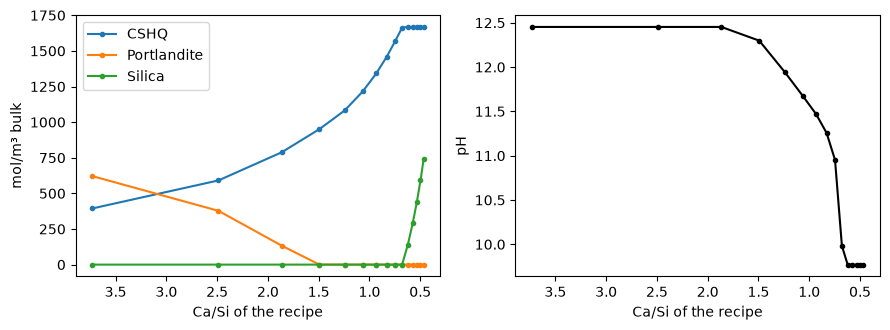

In [8]:
import matplotlib.pyplot as plt
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.4))
for name in ['CSHQ', 'Portlandite', 'Silica']:
    a1.plot(scan.Ca_Si, scan[name], 'o-', ms=3, label=name)
a1.set_xlabel('Ca/Si of the recipe'); a1.set_ylabel('mol/m³ bulk'); a1.invert_xaxis(); a1.legend()
a2.plot(scan.Ca_Si, scan.pH, 'o-', ms=3, color='k')
a2.set_xlabel('Ca/Si of the recipe'); a2.set_ylabel('pH'); a2.invert_xaxis()
plt.tight_layout(); plt.show()

从左到右，体相的 Ca/Si 逐渐降低，就像浆体因溶蚀失去 Ca 一样。portlandite 最先耗尽，随后 C-S-H 失去 Ca、pH 下降，在 Ca/Si 最低处出现无定形硅。耦合计算（教程 4）会逐个单元经历同样的顺序，因为 Ca 会向外扩散。

## `gibbs` 修正有什么作用？

`chemistry.gibbs` 只在 **内存中** 覆盖指定物种的标准摩尔 Gibbs 能 $G^\circ$（J/mol），不修改 GEMS 文件。本例使用的是其来源基准算例中的值。去掉这些修正后，同一配方给出的溶液不同：

In [9]:
case = yaml.safe_load(open('t02_equilibrium/case.yaml'))
case['chemistry']['gibbs'] = {}
case['output']['folder'] = 'results_no_gibbs'
yaml.safe_dump(case, open('t02_equilibrium/no_gibbs.yaml', 'w'), sort_keys=False)
subprocess.run(['python', '../FEniCSx_GEMS/coupling.py', 't02_equilibrium/no_gibbs.yaml'], check=True, capture_output=True)
for folder in ['results', 'results_no_gibbs']:
    r = pd.read_csv(f't02_equilibrium/{folder}/profiles.csv').iloc[0]
    print(f"{folder:17s} pH = {r.pH:.3f}   Ca = {r.Ca_c_mol_m3_water:.2f} mol/m3 water")

results           pH = 12.453   Ca = 19.35 mol/m3 water
results_no_gibbs  pH = 12.468   Ca = 20.23 mol/m3 water


除非有理由（例如复现已发表的基准算例）需要改动数据库，否则用 `gibbs: {}`。

## 自己试试

1. 把 `Silica-amorph` 从 `solid_phases` 中删去。输出的列有什么变化？
2. 写一个项目中没有的元素，例如 `Mg: 0.1`，读一读报错信息。
3. 设 `temperature: 323.15`（50 °C），比较 pH 和 portlandite。
4. 在 [Case Builder](../tools/case_builder.md) 中试一个配方：它用表单生成同样的 YAML。

**下一篇：** [教程 3](03_nacl_diffusion.ipynb) 用 `mode: coupled` 让两种 NaCl 溶液相互扩散：每一步都有输运和化学。